# H27: Exploratory Spatial Data Analysis of Reported Crime

## CI7340 Applied Data Programming — Coursework 1

**Research question:** How are reported crime incidents geographically distributed across Montgomery County, and how does the composition of broad crime categories vary between high-concentration and other areas?

**Purpose:** This notebook performs exploratory spatial data analysis (ESDA). It maps incident concentration, aggregates incidents into 1 km × 1 km grid cells, identifies the highest-concentration cells, and compares crime-category composition descriptively.

**Unit of analysis:** One row per incident (`Incident ID`), using the incident-level cleaned dataset.

**Scope:** Incidents with valid Montgomery County coordinates are retained. Records flagged as “Not a Crime” and generic NIBRS 90Z “All Other Offenses” are excluded from the primary crime analysis.

**Interpretation:** This analysis describes reported incident counts, not population-adjusted crime risk. The dataset does not provide population or footfall exposure denominators. Coordinates are generalised for privacy and must not be interpreted as exact incident addresses. No formal hypothesis test is required by the coursework brief; the analysis therefore focuses on descriptive and visual evidence.

## Output management and reliable real-map basemaps

Running the notebook from top to bottom creates `H27_Exploratory_Spatial_Data_Analysis` in the current working directory. It stores the filtered analysis dataset, grid summaries, descriptive tables, and static PNG figures. No interactive HTML map is generated.

**Basemap fix:** The previous version used OpenStreetMap's public tile server, which returned HTTP 403 because its volunteer-run tile service blocked the requests. This version uses **CARTO Positron** first and **Esri World Street Map** as a fallback. It deliberately does not call the blocked OpenStreetMap tile endpoint. An internet connection is required to retrieve basemap tiles.

Install dependencies if needed:

```bash
pip install -U contextily xyzservices pyproj pandas numpy matplotlib seaborn
```

If both tile providers are unavailable (for example, due to a restricted network), the map cells stop with a clear error rather than silently exporting a misleading map.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pyproj import Transformer

try:
    import contextily as ctx
except ImportError as exc:
    raise ImportError(
        "The real-map figures require contextily and xyzservices. "
        "Install them with: pip install -U contextily xyzservices"
    ) from exc

warnings.filterwarnings("ignore", category=FutureWarning)

NOTEBOOK_NAME = "H27_Exploratory_Spatial_Data_Analysis"
OUTPUT_DIR = Path.cwd() / NOTEBOOK_NAME
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DATA_PATH = Path("crime_dataset_incident_level_cleaned.csv")
GRID_SIZE_M = 1_000
HOTSPOT_PERCENTILE = 0.90
RANDOM_STATE = 42

# Avoid OpenStreetMap's public tile endpoint: it returned HTTP 403 in the prior run.
# Try CARTO first, then Esri. The helper reports a clear error if neither is reachable.
BASEMAP_SOURCES = [
    ("CARTO Positron", ctx.providers.CartoDB.Positron),
    ("Esri World Street Map", ctx.providers.Esri.WorldStreetMap),
]

def add_reliable_basemap(ax):
    """Add a street basemap using providers that do not use OSM's public tile endpoint."""
    failures = []
    for provider_name, provider in BASEMAP_SOURCES:
        try:
            ctx.add_basemap(
                ax,
                source=provider,
                crs="EPSG:3857",
                attribution_size=7,
                reset_extent=False,
                zorder=0,
            )
            return provider_name
        except Exception as exc:
            failures.append(f"{provider_name}: {type(exc).__name__}: {exc}")
    details = "\n".join(failures)
    raise RuntimeError(
        "Could not retrieve a basemap from CARTO or Esri. Check internet/proxy access "
        "and rerun the visualisation cell. No map image was exported.\n" + details
    )

sns.set_theme(style="whitegrid", context="notebook")
print(f"Output directory: {OUTPUT_DIR.resolve()}")
print(f"Dataset path: {DATA_PATH.resolve()}")
print("Basemap preference: CARTO Positron, then Esri World Street Map")

Output directory: D:\MSc\Applied Data Programming\CW 1\ADP-CW01-Group-17\notebooks\kavindu\H27_Exploratory_Spatial_Data_Analysis
Dataset path: D:\MSc\Applied Data Programming\CW 1\ADP-CW01-Group-17\notebooks\kavindu\crime_dataset_incident_level_cleaned.csv
Basemap preference: CARTO Positron, then Esri World Street Map


## 1. Load and validate the incident-level dataset

In [2]:

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Cannot find {DATA_PATH}. Place crime_dataset_incident_level_cleaned.csv "
        "in the same directory as this notebook, or update DATA_PATH."
    )

required_columns = [
    "Incident ID", "Crime Name1", "Crime Name2", "Latitude", "Longitude",
    "has_valid_coords", "is_not_a_crime", "is_90z_other"
]
df = pd.read_csv(DATA_PATH, usecols=lambda c: c in required_columns, low_memory=False)

missing_columns = sorted(set(required_columns) - set(df.columns))
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

print(f"Incident-level records loaded: {len(df):,}")
print(f"Unique incident IDs: {df['Incident ID'].nunique():,}")
print("\nCoordinate validity:")
print(df["has_valid_coords"].value_counts(dropna=False))


Incident-level records loaded: 467,601
Unique incident IDs: 467,601

Coordinate validity:
has_valid_coords
True     444866
False     22735
Name: count, dtype: int64


## 2. Geographic and analytical filtering

In [3]:

# Use the explicit validity flag and independently validate coordinate ranges.
df["Latitude"] = pd.to_numeric(df["Latitude"], errors="coerce")
df["Longitude"] = pd.to_numeric(df["Longitude"], errors="coerce")

valid_coordinates = (
    df["has_valid_coords"].fillna(False).astype(bool)
    & df["Latitude"].between(38.85, 39.40)
    & df["Longitude"].between(-77.60, -76.85)
)

geo_df = df.loc[valid_coordinates].copy()
geo_df = geo_df.drop_duplicates(subset="Incident ID")

# Primary analysis excludes records outside the intended crime scope.
geo_df["is_not_a_crime"] = geo_df["is_not_a_crime"].fillna(False).astype(bool)
geo_df["is_90z_other"] = geo_df["is_90z_other"].fillna(False).astype(bool)

crime_df = geo_df.loc[
    (~geo_df["is_not_a_crime"]) & (~geo_df["is_90z_other"])
].copy()

# Convert multi-category incident labels into an explicit "Multiple categories" group.
crime_df["Crime_Category"] = (
    crime_df["Crime Name1"].fillna("Unknown").astype(str).str.strip()
)
crime_df.loc[
    crime_df["Crime_Category"].str.contains(r"\|", regex=True),
    "Crime_Category"
] = "Multiple categories"

print(f"All incidents: {df['Incident ID'].nunique():,}")
print(f"Incidents with valid coordinates: {geo_df['Incident ID'].nunique():,}")
print(f"Primary analysis incidents: {crime_df['Incident ID'].nunique():,}")
print(f"Excluded for invalid coordinates: {df['Incident ID'].nunique() - geo_df['Incident ID'].nunique():,}")
print(f"Excluded as Not a Crime / generic 90Z: {len(geo_df) - len(crime_df):,}")

display(crime_df["Crime_Category"].value_counts().rename("Incident count").to_frame())


All incidents: 467,601
Incidents with valid coordinates: 444,866
Primary analysis incidents: 324,708
Excluded for invalid coordinates: 22,735
Excluded as Not a Crime / generic 90Z: 120,158


,Incident count
Crime_Category,
Crime Against Property,212649
Crime Against Society,63198
Crime Against Person,41093
Multiple categories,7768


## 3. Project coordinates and create 1 km grid cells

In [4]:

# Montgomery County is in UTM zone 18N. Projecting to metres makes grid dimensions meaningful.
transformer = Transformer.from_crs("EPSG:4326", "EPSG:26918", always_xy=True)
x_m, y_m = transformer.transform(
    crime_df["Longitude"].to_numpy(),
    crime_df["Latitude"].to_numpy()
)

crime_df["x_m"] = x_m
crime_df["y_m"] = y_m
crime_df["grid_x"] = np.floor(crime_df["x_m"] / GRID_SIZE_M).astype("int64")
crime_df["grid_y"] = np.floor(crime_df["y_m"] / GRID_SIZE_M).astype("int64")
crime_df["grid_id"] = (
    crime_df["grid_x"].astype(str) + "_" + crime_df["grid_y"].astype(str)
)

grid_counts = (
    crime_df.groupby(["grid_id", "grid_x", "grid_y"], observed=True)
    .size()
    .rename("incident_count")
    .reset_index()
)

grid_counts["center_x_m"] = (grid_counts["grid_x"] + 0.5) * GRID_SIZE_M
grid_counts["center_y_m"] = (grid_counts["grid_y"] + 0.5) * GRID_SIZE_M

inverse_transformer = Transformer.from_crs("EPSG:26918", "EPSG:4326", always_xy=True)
center_lon, center_lat = inverse_transformer.transform(
    grid_counts["center_x_m"].to_numpy(),
    grid_counts["center_y_m"].to_numpy()
)
grid_counts["center_longitude"] = center_lon
grid_counts["center_latitude"] = center_lat

threshold = grid_counts["incident_count"].quantile(HOTSPOT_PERCENTILE)
grid_counts["is_hotspot"] = grid_counts["incident_count"] >= threshold

# Use a quantile rank so the threshold and number of selected cells are transparent.
print(f"Occupied 1 km cells: {len(grid_counts):,}")
print(f"Hotspot threshold (90th percentile): {threshold:.0f} incidents per occupied cell")
print(f"Hotspot cells: {grid_counts['is_hotspot'].sum():,}")
print(f"Incidents in hotspot cells: {grid_counts.loc[grid_counts.is_hotspot, 'incident_count'].sum():,}")
print(f"Share of analysed incidents in hotspot cells: "
      f"{grid_counts.loc[grid_counts.is_hotspot, 'incident_count'].sum() / len(crime_df):.1%}")
display(grid_counts.sort_values("incident_count", ascending=False).head(15))


Occupied 1 km cells: 1,118
Hotspot threshold (90th percentile): 753 incidents per occupied cell
Hotspot cells: 112
Incidents in hotspot cells: 205,162
Share of analysed incidents in hotspot cells: 63.2%


,grid_id,grid_x,grid_y,incident_count,center_x_m,center_y_m,center_longitude,center_latitude,is_hotspot
941,324_4318,324,4318,9721,324500.0,4318500.0,-77.026604,38.997925,True
940,324_4317,324,4317,8696,324500.0,4317500.0,-77.026347,38.988920,True
890,322_4322,322,4322,7517,322500.0,4322500.0,-77.050726,39.033544,True
339,306_4341,306,4341,5824,306500.0,4341500.0,-77.240869,39.201230,True
891,322_4323,322,4323,5535,322500.0,4323500.0,-77.050986,39.042550,True
448,309_4335,309,4335,4373,309500.0,4335500.0,-77.204463,39.147867,True
768,318_4317,318,4317,3991,318500.0,4317500.0,-77.095581,38.987696,True
767,318_4316,318,4316,3931,318500.0,4316500.0,-77.095316,38.978691,True
710,316_4325,316,4325,3810,316500.0,4325500.0,-77.120811,39.059320,True
272,304_4339,304,4339,3630,304500.0,4339500.0,-77.263436,39.182774,True


## 4. Visualisation A — Incident density on a real street map

The incident density layer is overlaid on a real street basemap. Coordinates are transformed to Web Mercator (EPSG:3857), the projection used by web map tiles. The basemap helper tries CARTO Positron first and Esri World Street Map second.

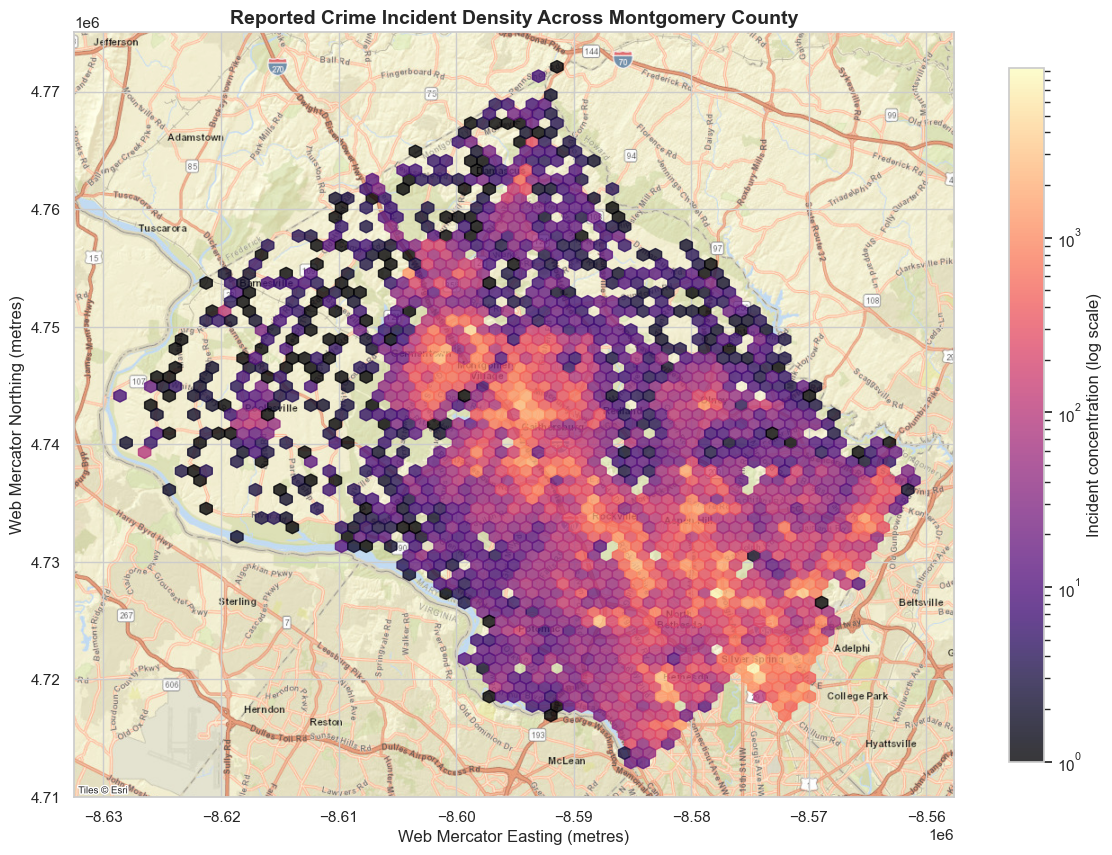

In [11]:

# Transform incident coordinates to Web Mercator for alignment with basemap tiles.
web_mercator = Transformer.from_crs(
    "EPSG:4326",
    "EPSG:3857",
    always_xy=True
)

x_web, y_web = web_mercator.transform(
    crime_df["Longitude"].to_numpy(),
    crime_df["Latitude"].to_numpy()
)

# Create the geographic incident-density visualisation.
fig, ax = plt.subplots(figsize=(12, 10))

# Plot incident density using a hexagonal binning layer.
hb = ax.hexbin(
    x_web,
    y_web,
    gridsize=65,
    mincnt=1,
    bins="log",
    cmap="magma",
    alpha=0.78,
    zorder=2
)

# Add the density colour scale.
fig.colorbar(
    hb,
    ax=ax,
    label="Incident concentration (log scale)",
    shrink=0.72
)

# Configure the map.
ax.set_title(
    "Reported Crime Incident Density Across Montgomery County",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Web Mercator Easting (metres)")
ax.set_ylabel("Web Mercator Northing (metres)")
ax.set_aspect("equal", adjustable="box")

# Add Esri World Street Map basemap.
ctx.add_basemap(
    ax,
    source=ctx.providers.Esri.WorldStreetMap,
    crs="EPSG:3857",
    attribution="Tiles © Esri",
    attribution_size=7,
    alpha=0.95,
    zorder=0
)

# Improve layout and export the figure.
fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "h27_figure_1_geographic_incident_density_osm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 5. Visualisation B — 1 km hotspot grid on a real street map

Each point represents the centroid of an occupied 1 km grid cell. Colour indicates the incident count, and red outlines identify the top-decile concentration cells. The real-map background provides roads and place-name context.

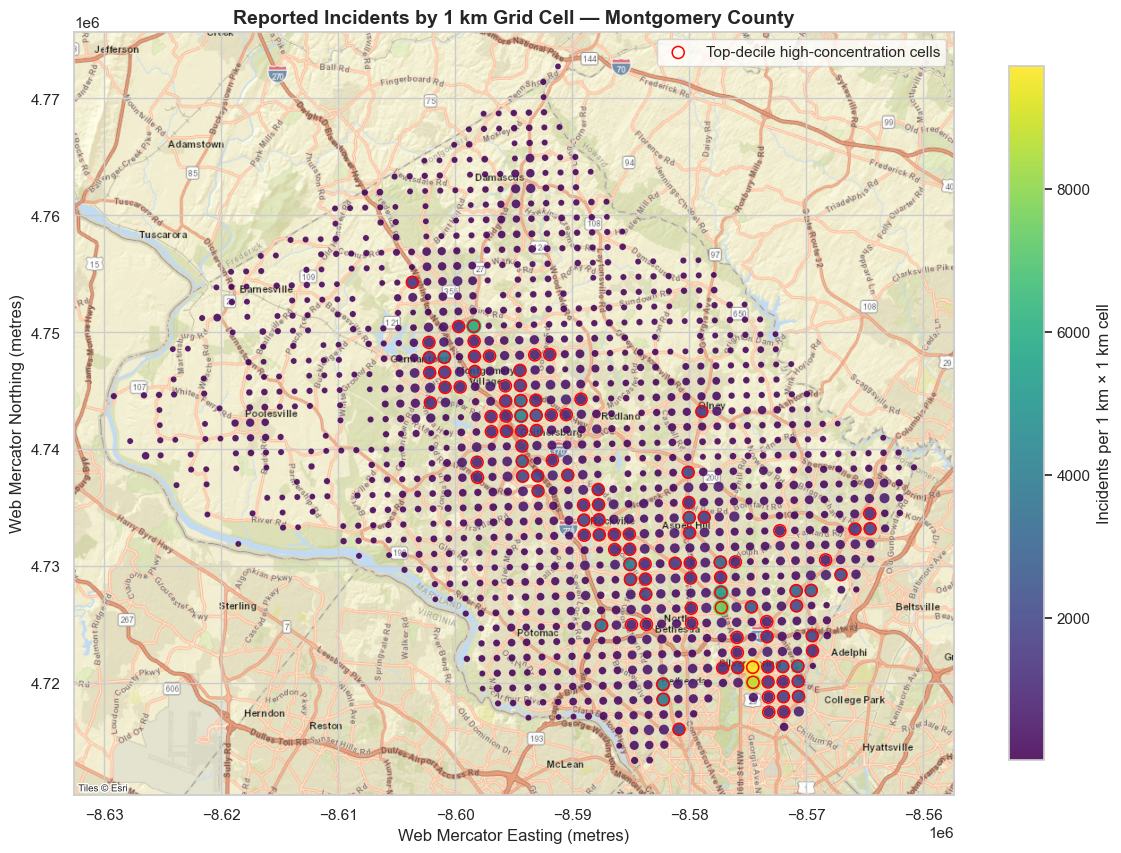

In [12]:

# Convert grid-cell centroids from UTM Zone 18N to Web Mercator.
utm_to_web = Transformer.from_crs(
    "EPSG:26918",
    "EPSG:3857",
    always_xy=True
)

centroid_web_x, centroid_web_y = utm_to_web.transform(
    grid_counts["center_x_m"].to_numpy(),
    grid_counts["center_y_m"].to_numpy()
)

# Prepare grid-cell coordinates for visualisation.
plot_grid = grid_counts.assign(
    web_x=centroid_web_x,
    web_y=centroid_web_y
)

# Separate high-concentration cells.
hot = plot_grid.loc[plot_grid["is_hotspot"]]

# Create the hotspot map.
fig, ax = plt.subplots(figsize=(12, 10))

# Plot all occupied 1 km grid cells.
scatter = ax.scatter(
    plot_grid["web_x"],
    plot_grid["web_y"],
    c=plot_grid["incident_count"],
    s=18 + 1.5 * np.sqrt(plot_grid["incident_count"]),
    cmap="viridis",
    alpha=0.88,
    edgecolors="white",
    linewidths=0.2,
    zorder=2
)

# Highlight top-decile high-concentration cells.
ax.scatter(
    hot["web_x"],
    hot["web_y"],
    facecolors="none",
    edgecolors="red",
    linewidths=1.1,
    s=75,
    label="Top-decile high-concentration cells",
    zorder=3
)

# Add the incident-count colour scale.
fig.colorbar(
    scatter,
    ax=ax,
    label="Incidents per 1 km × 1 km cell",
    shrink=0.72
)

# Configure the map.
ax.set_title(
    "Reported Incidents by 1 km Grid Cell — Montgomery County",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Web Mercator Easting (metres)")
ax.set_ylabel("Web Mercator Northing (metres)")
ax.set_aspect("equal", adjustable="box")
ax.legend(loc="upper right")

# Add Esri World Street Map basemap.
ctx.add_basemap(
    ax,
    source=ctx.providers.Esri.WorldStreetMap,
    crs="EPSG:3857",
    attribution="Tiles © Esri",
    attribution_size=7,
    alpha=0.95,
    zorder=0
)

# Improve layout and export the figure.
fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "h27_figure_2_hotspot_grid_osm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 6. Descriptive comparison of crime-category composition by location group

In [7]:
# Attach each incident to its grid-cell classification for descriptive comparison.
incident_analysis = crime_df.merge(
    grid_counts[["grid_id", "incident_count", "is_hotspot"]],
    on="grid_id", how="left", validate="many_to_one"
)
incident_analysis["Location_Group"] = np.where(
    incident_analysis["is_hotspot"], "High-concentration cells", "Other occupied cells"
)

category_counts = pd.crosstab(
    incident_analysis["Location_Group"], incident_analysis["Crime_Category"]
)
category_percentages = pd.crosstab(
    incident_analysis["Location_Group"], incident_analysis["Crime_Category"],
    normalize="index"
) * 100

print(f"Incidents included in descriptive comparison: {len(incident_analysis):,}")
print("\nIncident counts by location group:")
display(incident_analysis["Location_Group"].value_counts().rename("Incident_Count").to_frame())
print("\nCrime-category counts by location group:")
display(category_counts)
print("\nCrime-category percentages within each location group:")
display(category_percentages.round(2))

Incidents included in descriptive comparison: 324,708

Incident counts by location group:


,Incident_Count
Location_Group,
High-concentration cells,205162
Other occupied cells,119546



Crime-category counts by location group:


Crime_Category,Crime Against Person,Crime Against Property,Crime Against Society,Multiple categories
Location_Group,,,,
High-concentration cells,25297,129242,44657,5966
Other occupied cells,15796,83407,18541,1802



Crime-category percentages within each location group:


Crime_Category,Crime Against Person,Crime Against Property,Crime Against Society,Multiple categories
Location_Group,,,,
High-concentration cells,12.33,63.00,21.77,2.91
Other occupied cells,13.21,69.77,15.51,1.51


## 7. Visualisation C — Crime-category composition by location group

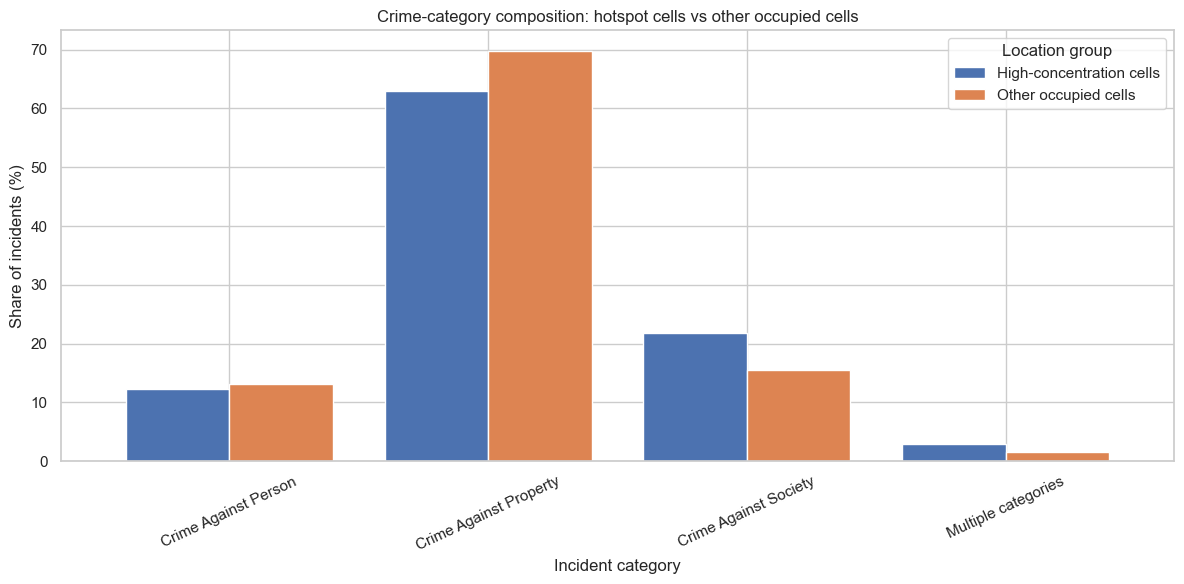

In [8]:

composition = pd.crosstab(
    incident_analysis["Location_Group"],
    incident_analysis["Crime_Category"],
    normalize="index"
) * 100

fig, ax = plt.subplots(figsize=(12, 6))
composition.T.plot(kind="bar", ax=ax, width=0.8)
ax.set_title("Crime-category composition: hotspot cells vs other occupied cells")
ax.set_xlabel("Incident category")
ax.set_ylabel("Share of incidents (%)")
ax.tick_params(axis="x", rotation=25)
ax.legend(title="Location group")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "h27_figure_3_category_composition.png",
            dpi=300, bbox_inches="tight")
plt.show()


## 8. Descriptive findings and interpretation

In [9]:
# Summarise the spatial concentration and category composition without inferential testing.
location_summary = (
    incident_analysis.groupby("Location_Group")
    .agg(
        Incident_Count=("Incident ID", "nunique"),
        Grid_Cell_Count=("grid_id", "nunique"),
        Mean_Incidents_Per_Incident_Cell=("incident_count", "mean")
    )
    .reset_index()
)
location_summary["Incident_Share_Percent"] = (
    location_summary["Incident_Count"] / location_summary["Incident_Count"].sum() * 100
)
display(location_summary.round(2))

print("Interpret the category percentage chart descriptively: compare the relative share of each category across the two location groups.")

,Location_Group,Incident_Count,Grid_Cell_Count,Mean_Incidents_Per_Incident_Cell,Incident_Share_Percent
0,High-concentration cells,205162,112,3052.91,63.18
1,Other occupied cells,119546,1006,356.64,36.82


Interpret the category percentage chart descriptively: compare the relative share of each category across the two location groups.


## 9. Interpretation and limitations


Use the maps, grid summaries, incident counts, and category percentages as descriptive evidence. The top-decile grid cells represent areas with the highest recorded incident counts in this dataset; they should not be described as higher-risk areas without suitable population or exposure denominators.

### Limitations to state in the report

1. The 1 km grid and top-decile threshold are analytical choices. A different cell size or percentile may produce different hotspot patterns.
2. The analysis uses incident counts, not population- or footfall-adjusted rates. High counts may partly reflect more people, businesses, roads, or reporting opportunities.
3. Coordinates are block-level/generalised for privacy. Multiple incidents can share coordinates, and the map does not represent exact incident addresses.
4. The analysis excludes invalid-coordinate incidents and, in its primary version, non-crime and generic 90Z records. Report the resulting sample size and exclusions.
5. Incidents involving multiple broad categories are grouped as “Multiple categories”.

For a stronger follow-up, repeat the analysis with 500 m and 2 km grid sizes and compare the effect sizes. Do not describe a hotspot as a high-risk neighbourhood without suitable population/exposure denominators.


## 10. Export datasets, descriptive tables, and figures

In [10]:
# Save the analysis-ready incident data, spatial grid summaries, descriptive tables, and figures.
export_columns = [
    "Incident ID", "Crime Name1", "Crime Name2", "Crime_Category",
    "Latitude", "Longitude", "x_m", "y_m", "grid_id",
    "incident_count", "is_hotspot", "Location_Group"
]
incident_analysis[export_columns].to_csv(
    OUTPUT_DIR / "h27_spatial_incident_analysis_dataset.csv", index=False
)
grid_counts.to_csv(OUTPUT_DIR / "h27_1km_grid_incident_counts.csv", index=False)
category_counts.to_csv(OUTPUT_DIR / "h27_hotspot_category_counts.csv")
category_percentages.to_csv(OUTPUT_DIR / "h27_hotspot_category_percentages.csv")
location_summary.to_csv(OUTPUT_DIR / "h27_location_group_summary.csv", index=False)

print(f"All H27 outputs saved to: {OUTPUT_DIR.resolve()}")
print("\nFiles:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print(f"- {path.name}")

All H27 outputs saved to: D:\MSc\Applied Data Programming\CW 1\ADP-CW01-Group-17\notebooks\kavindu\H27_Exploratory_Spatial_Data_Analysis

Files:
- h27_1km_grid_incident_counts.csv
- h27_figure_1_geographic_incident_density.png
- h27_figure_1_geographic_incident_density_carto_positron.png
- h27_figure_1_geographic_incident_density_osm.png
- h27_figure_2_hotspot_grid.png
- h27_figure_2_hotspot_grid_carto_positron.png
- h27_figure_2_hotspot_grid_osm.png
- h27_figure_3_category_composition.png
- h27_hotspot_category_counts.csv
- h27_hotspot_category_percentages.csv
- h27_location_group_summary.csv
- h27_spatial_incident_analysis_dataset.csv
